In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
cols = ["age","sex","cp","trestbps","chol","fbs","restecg",
        "thalach","exang","oldpeak","slope","ca","thal","num"]

df = pd.read_csv("../data/raw/processed.cleveland.data",
                 header=None, names=cols, na_values="?")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

In [4]:
for c in ["ca", "thal"]:
    df[c] = df[c].fillna(df[c].mode()[0])

df.isnull().sum().sum()   # should print 0

np.int64(0)

**Missing values:** 6 of the 303 rows (about 2%) had a missing value: 4 in `ca` and 2 in `thal`. I filled them with the mode (most frequent value) instead of dropping the rows. Both columns are categories or small counts (`ca` = 0–3 vessels, `thal` = 3/6/7), so a mean such as 0.67 vessels would not be a valid value, and filling keeps all 303 patients in a small dataset.

In [5]:
df["target"] = (df["num"] > 0).astype(int)   # 0 = no disease, 1 = disease
df = df.drop(columns="num")
df["target"].value_counts()

target
0    164
1    139
Name: count, dtype: int64

In [6]:
df.to_csv("../data/processed/heart_clean.csv", index=False)

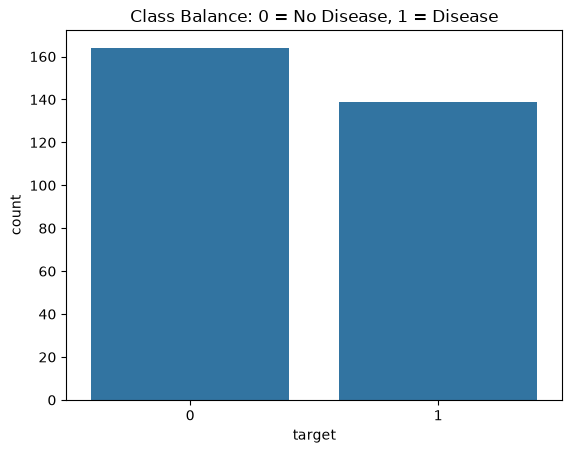

In [7]:
sns.countplot(x="target", data=df)
plt.title("Class Balance: 0 = No Disease, 1 = Disease")
plt.savefig("../screenshots/class_balance.png")
plt.show()

**Observations (class balance):** The classes are roughly balanced: 164 patients without disease (54%) and 139 with disease (46%). No special balancing technique (oversampling or class weights) is needed. A model that always predicts "no disease" would reach only 54% accuracy, so that is the baseline the models must beat.

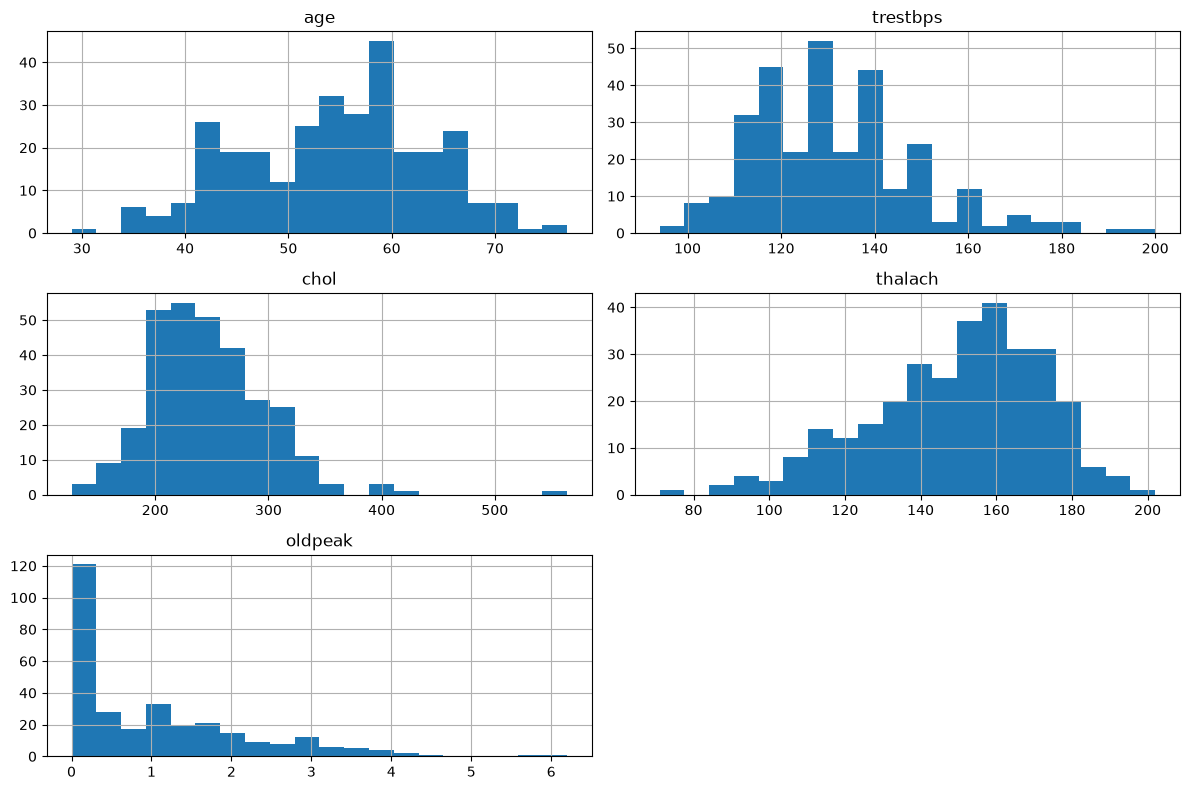

In [8]:
num_cols = ["age","trestbps","chol","thalach","oldpeak"]
df[num_cols].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.savefig("../screenshots/histograms.png")
plt.show()

**Observations (histograms):** Most patients are between 48 and 61 years old (range 29–77, median 56). `chol` is mostly 211–275 but has a long right tail with a few outliers up to 564. `oldpeak` has a large spike at 0 (99 patients, about a third), and the features use very different scales (e.g. `chol` in the hundreds vs `oldpeak` 0–6), which is why the numeric features are scaled before modelling.

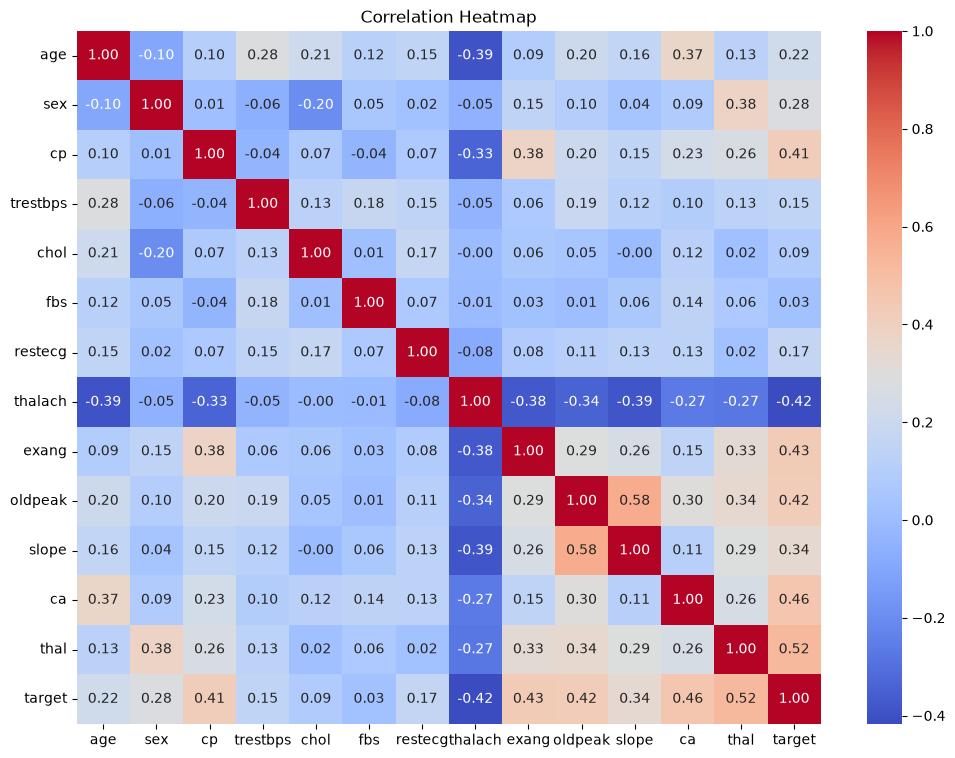

In [9]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.savefig("../screenshots/correlation_heatmap.png")
plt.show()

**Observations (correlation heatmap):** In the `target` row, the strongest positive correlations are `thal` (0.52), `ca` (0.46) and `exang` (0.43), followed by `oldpeak` (0.42) and `cp` (0.41). `thalach` (maximum heart rate) is clearly negative (−0.42): patients who reach a higher heart rate during exercise are less likely to have disease. `fbs` (0.03) and `chol` (0.09) are close to 0, so on their own they carry little signal in this dataset. `cp`, `thal`, `restecg` and `slope` are categories, so their correlation values only give a rough indication.